In [1]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

# input dari Data Preparation: data bersih dengan pembagian train dan test
data = pd.read_csv("../data/kbbi_bersih.csv")
train = data[data["split"] == "train"]
test = data[data["split"] == "test"]      # tidak disentuh sampai tahap testing
print(len(train), len(test))

79424 19857


In [2]:
# 1. model selection: tiga kandidat untuk klasifikasi kelas kata
def tfidf():
    return TfidfVectorizer(max_features=3000, min_df=2)

kandidat = {
    "KNN": make_pipeline(tfidf(), KNeighborsClassifier(n_neighbors=5, metric="cosine")),
    "Random Forest": make_pipeline(tfidf(), RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)),
    "SVM": make_pipeline(tfidf(), LinearSVC(random_state=42)),
}

# seleksi memakai 12.000 data latih saja supaya cepat, validasi diambil dari data latih
sampel = train.sample(12000, random_state=42)
X_fit, X_val, y_fit, y_val = train_test_split(
    sampel["submakna"], sampel["kelas_utama"], test_size=0.2, random_state=42, stratify=sampel["kelas_utama"])
print(len(X_fit), len(X_val))

9600 2400


In [3]:
# 2. model training: setiap kandidat belajar dari data latih
for nama, model in kandidat.items():
    model.fit(X_fit, y_fit)
    print(f"{nama} selesai dilatih")

KNN selesai dilatih
Random Forest selesai dilatih
SVM selesai dilatih


In [4]:
# 3. model validation: adu performa pada data validasi
hasil = pd.DataFrame({
    "Akurasi latih": {n: accuracy_score(y_fit, m.predict(X_fit)) for n, m in kandidat.items()},
    "Akurasi validasi": {n: accuracy_score(y_val, m.predict(X_val)) for n, m in kandidat.items()},
}).sort_values("Akurasi validasi", ascending=False)

pemenang = hasil.index[0]
print("Pemenang:", pemenang)
hasil.round(3)

Pemenang: SVM


,Akurasi latih,Akurasi validasi
SVM,0.903,0.805
Random Forest,0.946,0.795
KNN,0.811,0.733


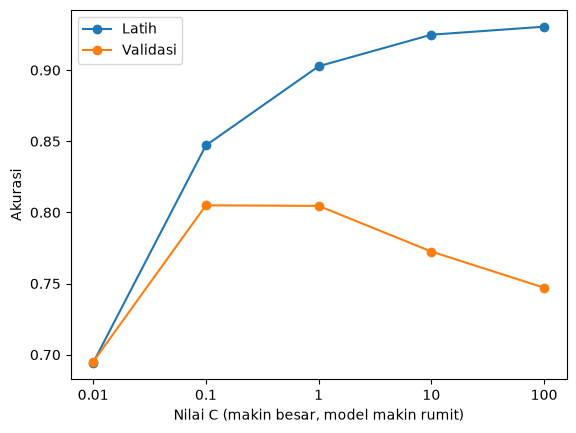

C terbaik: 0.1


In [5]:
# hyperparameter tuning pemenang (parameter C pada SVM), sekaligus melihat underfitting dan overfitting
daftar_C = [0.01, 0.1, 1, 10, 100]
skor_latih, skor_val = [], []

for c in daftar_C:
    m = make_pipeline(tfidf(), LinearSVC(C=c, random_state=42, max_iter=5000)).fit(X_fit, y_fit)
    skor_latih.append(accuracy_score(y_fit, m.predict(X_fit)))
    skor_val.append(accuracy_score(y_val, m.predict(X_val)))

plt.plot(range(len(daftar_C)), skor_latih, marker="o", label="Latih")
plt.plot(range(len(daftar_C)), skor_val, marker="o", label="Validasi")
plt.xticks(range(len(daftar_C)), daftar_C)
plt.xlabel("Nilai C (makin besar, model makin rumit)")
plt.ylabel("Akurasi")
plt.legend()
plt.show()

C_terbaik = daftar_C[skor_val.index(max(skor_val))]
print("C terbaik:", C_terbaik)

### Analisis validasi

SVM menang dengan akurasi validasi 80,4 persen, disusul Random Forest 79,2 persen dan KNN 73,5 persen. Pemenangnya berbeda dari contoh di materi karena jenis datanya teks: SVM memang cocok untuk fitur TF-IDF yang jumlahnya banyak, sedangkan Random Forest lebih cocok untuk data tabel. Ini contoh bahwa tidak ada satu algoritma yang terbaik untuk semua masalah.

Random Forest menunjukkan tanda overfitting karena akurasi latihnya 94,6 persen tetapi akurasi validasinya hanya 79,2 persen. Pada grafik tuning, C yang terlalu kecil (0,01) membuat akurasi latih dan validasi sama-sama rendah, yaitu underfitting. Sebaliknya, pada C 10 ke atas akurasi latih naik di atas 92 persen sementara akurasi validasi turun, yaitu overfitting. Nilai C 0,1 memberi akurasi validasi tertinggi, jadi itu yang dipakai.

In [6]:
# 4. model testing: model terbaik dilatih ulang pada seluruh data latih, lalu diuji satu kali pada data uji
final = make_pipeline(tfidf(), LinearSVC(C=C_terbaik, random_state=42, max_iter=5000))
final.fit(train["submakna"], train["kelas_utama"])

pred = final.predict(test["submakna"])
print(f"Akurasi data uji: {accuracy_score(test['kelas_utama'], pred):.1%}")
print(classification_report(test["kelas_utama"], pred))

Akurasi data uji: 82.9%
              precision    recall  f1-score   support

   Adjektiva       0.78      0.52      0.62      2117
      Nomina       0.83      0.96      0.89     12171
       Verba       0.84      0.65      0.73      5569

    accuracy                           0.83     19857
   macro avg       0.82      0.71      0.75     19857
weighted avg       0.83      0.83      0.82     19857



In [7]:
# 5. model deployment: simpan model lalu bungkus dalam fungsi yang meniru endpoint POST /predict
joblib.dump(final, "../models/model_kelas_final.joblib")
model_api = joblib.load("../models/model_kelas_final.joblib")

def predict(input_json):
    prediksi = model_api.predict(input_json["data"]).tolist()
    return {"prediksi": prediksi}

predict({"data": ["orang yang mengajar di sekolah", "melakukan sesuatu dengan cepat", "tidak memiliki sifat yang baik"]})

{'prediksi': ['Nomina', 'Verba', 'Adjektiva']}

### Analisis hasil

Akurasi pada data uji adalah 82,9 persen, sedikit di atas skor validasi karena model final dilatih ulang pada seluruh data latih (79.424 data) dan bukan hanya 12.000 data. Skor ini lebih rendah dari akurasi di Data Preparation karena di sini hanya teks makna yang dipakai tanpa fitur tambahan seperti awalan dan panjang makna.

Nomina terbaca paling baik (recall 0,96), sedangkan adjektiva paling sulit (recall 0,52) karena datanya paling sedikit dan maknanya sering mirip dengan kelas lain. Data uji hanya dipakai satu kali pada tahap testing, jadi angka ini bisa dilaporkan sebagai performa model pada data baru.

In [8]:
# refleksi: mengapa data uji tidak boleh dipakai untuk validasi?
pd.DataFrame({
    "Tahap": ["Validasi (try-out)", "Testing (ujian akhir)"],
    "Data": ["Sebagian data latih", "Data uji yang disimpan rapat"],
    "Fungsi": ["Memilih model dan setelannya, boleh dipakai berkali-kali", "Mengukur performa nyata, hanya sekali"],
    "Jika tertukar": ["Tidak masalah", "Skor ujian terlalu bagus karena model sudah menyesuaikan diri dengan soalnya, jadi tidak bisa dipercaya"],
})

,Tahap,Data,Fungsi,Jika tertukar
0,Validasi (try-out),Sebagian data latih,"Memilih model dan setelannya, boleh dipakai be...",Tidak masalah
1,Testing (ujian akhir),Data uji yang disimpan rapat,"Mengukur performa nyata, hanya sekali",Skor ujian terlalu bagus karena model sudah me...
